In [17]:
import torch

In [18]:
from diffusers import StableDiffusionInpaintPipeline

MODEL_PATH = "models/stable-diffusion-inpainting"

In [19]:
!ls

/bin/bash: warning: setlocale: LC_ALL: cannot change locale (en_US.UTF-8): No such file or directory
README.md    exploring_CLAP.ipynb  resources  stablediffusioninpainting.ipynb
data	     models		   runs       tests
dataloaders  outputs		   scripts


In [20]:
pipe = StableDiffusionInpaintPipeline.from_pretrained(
    MODEL_PATH,
    dtype=torch.float16,
    variant="fp16",
    use_safetensors=True,
    safety_checker=None,
    feature_extractor=None,
).to("cuda")

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_inpaint.StableDiffusionInpaintPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


In [21]:
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display


In [22]:
image = Image.open("data/avsbench_data_processed/Single-source/s4_data/visual_frames/test/dog_barking/4x2OdlSk5Ms/4x2OdlSk5Ms_1.png").convert("RGB")
mask = Image.open("data/avsbench_data_processed/Single-source/s4_data/gt_masks/test/dog_barking/4x2OdlSk5Ms/4x2OdlSk5Ms_1.png").convert("L")

  0%|          | 0/30 [00:00<?, ?it/s]

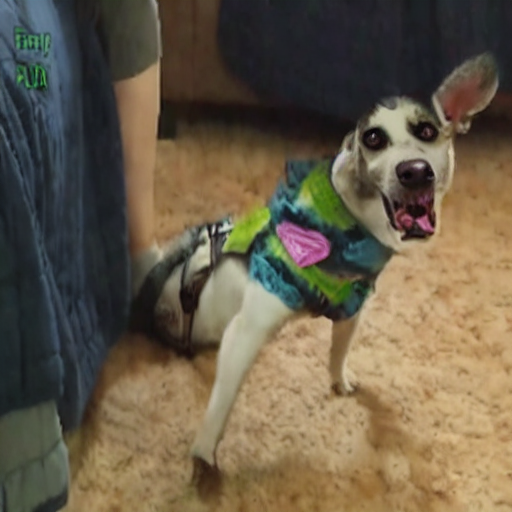

In [32]:
prompt = "dog"

result = pipe(
    prompt=prompt,
    image=image,
    mask_image=mask,
    num_inference_steps=30,
    guidance_scale=7.5,
).images[0]
display(result)
result.save("diffusionoutput.png")

In [12]:
output = Image.open("diffusionoutput.png")

FileNotFoundError: [Errno 2] No such file or directory: 'diffusionoutput.png'